# Exploratory data analysis: booking behavior and cancellation patterns

This notebook extends the initial profiling and claim checks with visual, business-oriented exploration. Each section calculates a summary first, displays it, and then plots the same result. It is descriptive only: it does not select model features or train a model.


In [16]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

SRC_DIR = Path.cwd().parent / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
import data

plt.style.use("seaborn-v0_8-whitegrid")
bookings = data.read_raw()
bookings["arrival_date"] = data.arrival_date(bookings)
bookings["nights"] = bookings["stays_in_weekend_nights"] + bookings["stays_in_week_nights"]
bookings["arrival_month"] = bookings["arrival_date"].dt.month
bookings["arrival_month_name"] = bookings["arrival_date"].dt.strftime("%b")
print(f"Loaded {len(bookings):,} bookings")


Loaded 119,390 bookings


## 1. When are the hotels busiest?

Monthly booking volume helps show seasonal demand. We calculate monthly arrivals overall and by hotel before plotting them.


In [17]:
monthly_volume = bookings.groupby(["arrival_date", "hotel"]).size().unstack(fill_value=0)
monthly_volume = monthly_volume.resample("MS").sum()
print(monthly_volume.describe().round(1))
display(monthly_volume.head())


hotel  City Hotel  Resort Hotel
count        26.0          26.0
mean       3051.2        1540.8
std         911.7         251.0
min        1235.0         884.0
25%        2478.5        1379.0
50%        3254.5        1564.5
75%        3647.2        1751.0
max        4556.0        1984.0


hotel,City Hotel,Resort Hotel
arrival_date,,
2015-07-01,1398,1378
2015-08-01,2480,1409
2015-09-01,3529,1585
2015-10-01,3386,1571
2015-11-01,1235,1105


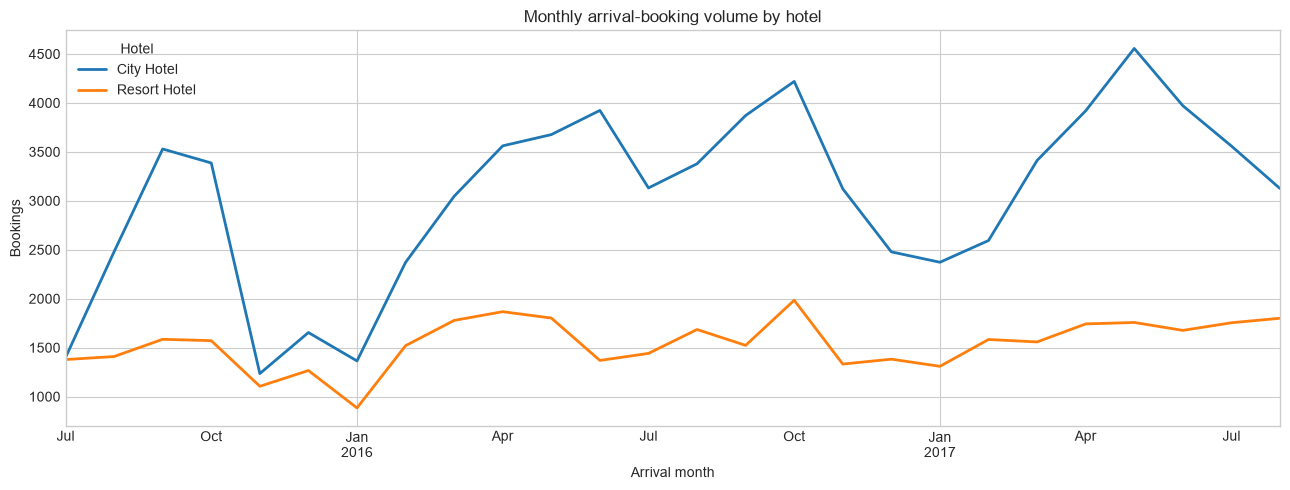

In [18]:
fig, ax = plt.subplots(figsize=(13, 5))
monthly_volume.plot(ax=ax, linewidth=2)
ax.set_title("Monthly arrival-booking volume by hotel")
ax.set_xlabel("Arrival month")
ax.set_ylabel("Bookings")
ax.legend(title="Hotel")
fig.tight_layout()
plt.show()


## 2. Does cancellation behavior change by arrival month?

The monthly cancellation rate is more useful than volume alone because the overbooking problem depends on how many bookings fail to arrive.


In [19]:
monthly_cancellation = bookings.groupby(["arrival_month", "hotel"])["is_canceled"].mean().unstack() * 100
monthly_cancellation.index = [pd.Timestamp(year=2000, month=int(month), day=1).strftime("%b") for month in monthly_cancellation.index]
print(monthly_cancellation.round(2))


hotel  City Hotel  Resort Hotel
Jan         39.67         14.82
Feb         38.29         25.62
Mar         36.95         22.87
Apr         46.32         29.34
May         44.38         28.77
Jun         44.69         33.07
Jul         40.88         31.40
Aug         40.10         33.45
Sep         42.03         32.37
Oct         42.97         27.51
Nov         38.12         18.92
Dec         42.11         23.83


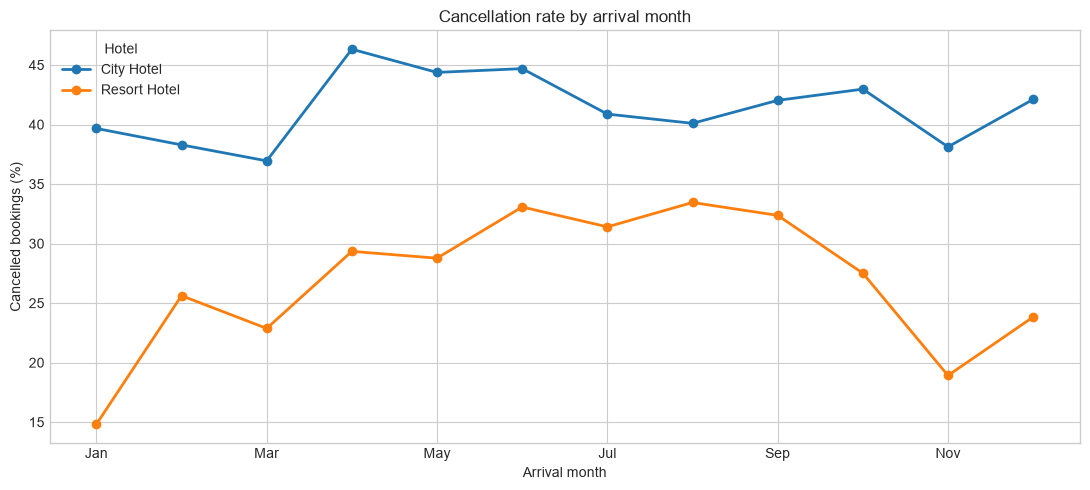

In [20]:
fig, ax = plt.subplots(figsize=(11, 5))
monthly_cancellation.plot(ax=ax, marker="o", linewidth=2)
ax.set_title("Cancellation rate by arrival month")
ax.set_xlabel("Arrival month")
ax.set_ylabel("Cancelled bookings (%)")
ax.legend(title="Hotel")
fig.tight_layout()
plt.show()


## 3. How does booking lead time relate to cancellations?

We group bookings by how far ahead they were made. This shows whether long-lead bookings behave differently from last-minute bookings.


In [21]:
lead_bins = [-1, 7, 30, 90, 180, 365, float("inf")]
lead_labels = ["0-7", "8-30", "31-90", "91-180", "181-365", "366+"]
bookings["lead_time_band"] = pd.cut(bookings["lead_time"], bins=lead_bins, labels=lead_labels)
lead_summary = bookings.groupby("lead_time_band", observed=False)["is_canceled"].agg(bookings="size", cancellation_rate="mean")
lead_summary["cancellation_rate_pct"] = lead_summary["cancellation_rate"] * 100
display(lead_summary.round(3))


,bookings,cancellation_rate,cancellation_rate_pct
lead_time_band,,,
0-7,19746,0.096,9.632
8-30,18960,0.279,27.864
31-90,29553,0.377,37.698
91-180,26439,0.447,44.710
181-365,21544,0.555,55.454
366+,3148,0.677,67.662


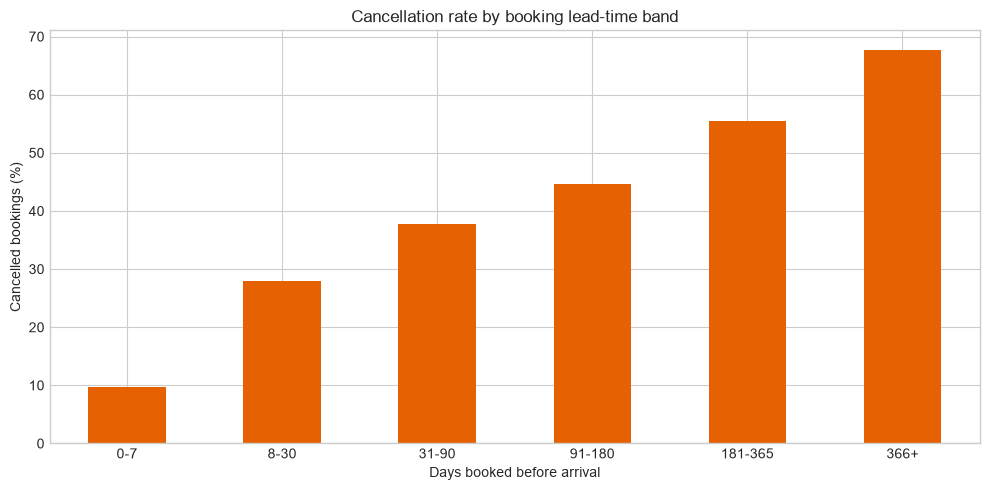

In [22]:
fig, ax = plt.subplots(figsize=(10, 5))
lead_summary["cancellation_rate_pct"].plot.bar(ax=ax, color="#e66101")
ax.set_title("Cancellation rate by booking lead-time band")
ax.set_xlabel("Days booked before arrival")
ax.set_ylabel("Cancelled bookings (%)")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()


## 4. What is the typical length of stay?

Length of stay affects booking value and helps explain how different hotel demand patterns may be.


In [23]:
stay_summary = bookings.groupby("hotel")["nights"].agg(bookings="size", mean="mean", median="median", maximum="max")
display(stay_summary.round(2))


,bookings,mean,median,maximum
hotel,,,,
City Hotel,79330,2.98,3.0,57
Resort Hotel,40060,4.32,3.0,69


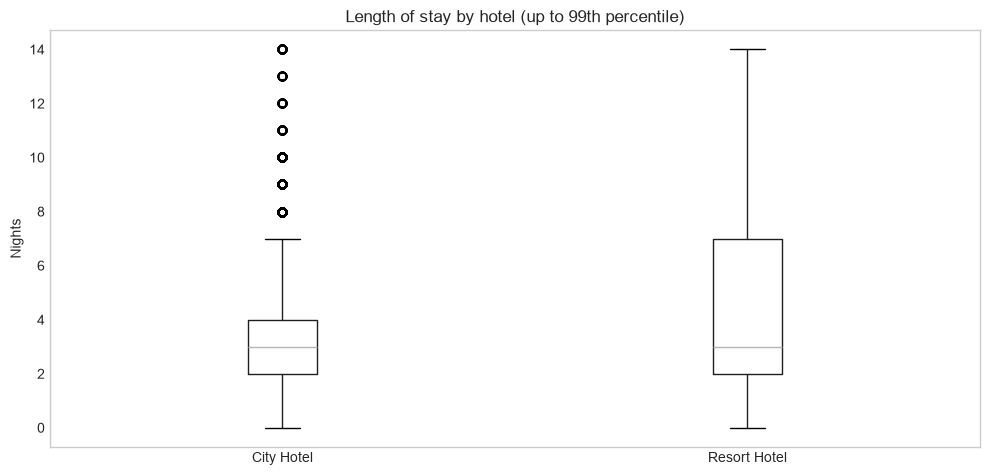

In [24]:
fig, ax = plt.subplots(figsize=(10, 5))
plot_stays = bookings.loc[bookings["nights"] <= bookings["nights"].quantile(0.99)]
plot_stays.boxplot(column="nights", by="hotel", ax=ax, grid=False)
ax.set_title("Length of stay by hotel (up to 99th percentile)")
ax.set_xlabel("")
ax.set_ylabel("Nights")
fig.suptitle("")
fig.tight_layout()
plt.show()


## 5. Which booking channels bring volume and cancellations?

We calculate both booking volume and cancellation rate by distribution channel. A small channel with an extreme rate should not be interpreted without its sample size.


In [25]:
channel_summary = bookings.groupby("distribution_channel")["is_canceled"].agg(bookings="size", cancelled="sum", cancellation_rate="mean").sort_values("bookings", ascending=False)
channel_summary["cancellation_rate_pct"] = channel_summary["cancellation_rate"] * 100
display(channel_summary.round(3))


,bookings,cancelled,cancellation_rate,cancellation_rate_pct
distribution_channel,,,,
TA/TO,97870,40152,0.410,41.026
Direct,14645,2557,0.175,17.460
Corporate,6677,1474,0.221,22.076
GDS,193,37,0.192,19.171
Undefined,5,4,0.800,80.000


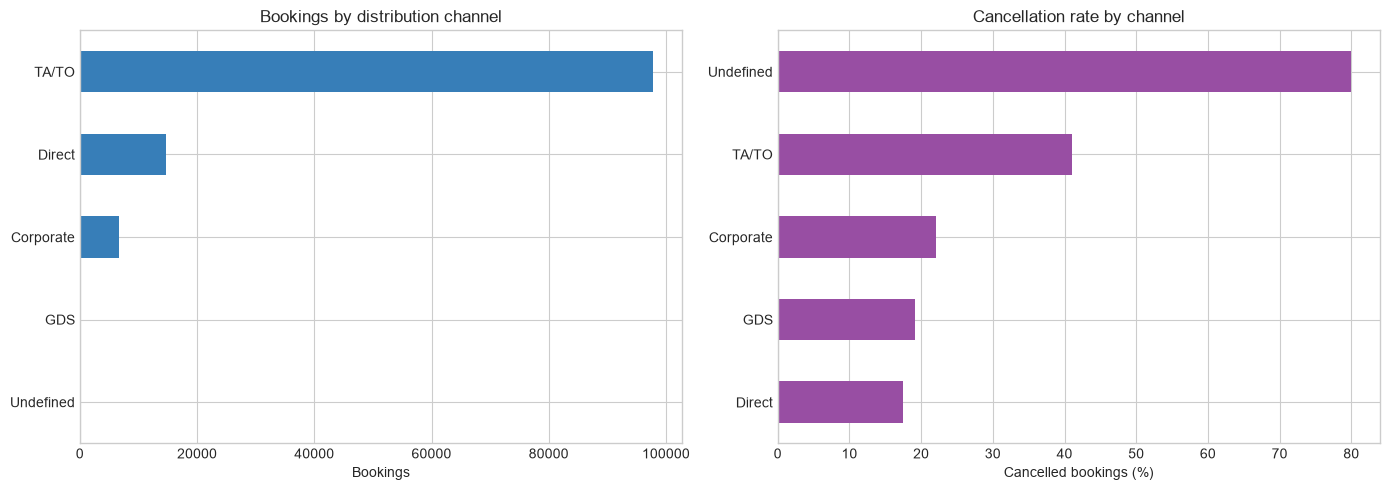

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
channel_summary.sort_values("bookings")["bookings"].plot.barh(ax=axes[0], color="#377eb8")
axes[0].set_title("Bookings by distribution channel")
axes[0].set_xlabel("Bookings")
axes[0].set_ylabel("")
channel_summary.sort_values("cancellation_rate_pct")["cancellation_rate_pct"].plot.barh(ax=axes[1], color="#984ea3")
axes[1].set_title("Cancellation rate by channel")
axes[1].set_xlabel("Cancelled bookings (%)")
axes[1].set_ylabel("")
fig.tight_layout()
plt.show()


## 6. How does price vary by hotel and cancellation outcome?

ADR is shown descriptively here. It remains a scoring value and its feature-timing treatment is documented separately in the column audit.


In [27]:
adr_summary = bookings.groupby(["hotel", "is_canceled"])["adr"].agg(bookings="size", median="median", mean="mean")
display(adr_summary.round(2))


bookings  median    mean
hotel        is_canceled                          
City Hotel   0               46228    99.9  105.75
             1               33102    99.8  104.69
Resort Hotel 0               28938    72.0   90.79
             1               11122    84.0  105.79

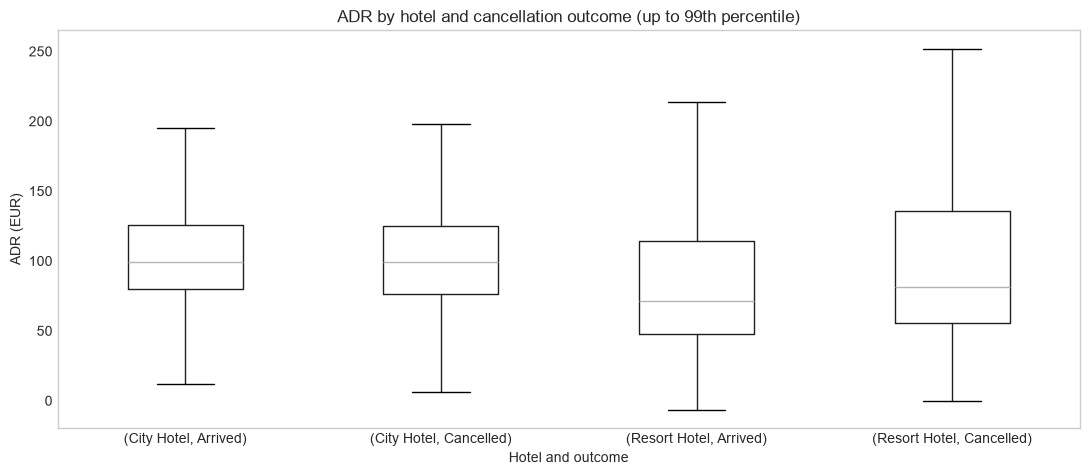

In [28]:
fig, ax = plt.subplots(figsize=(11, 5))
adr_plot = bookings.loc[bookings["adr"] <= bookings["adr"].quantile(0.99)].copy()
adr_plot["outcome"] = adr_plot["is_canceled"].map({0: "Arrived", 1: "Cancelled"})
adr_plot.boxplot(column="adr", by=["hotel", "outcome"], ax=ax, grid=False, showfliers=False)
ax.set_title("ADR by hotel and cancellation outcome (up to 99th percentile)")
ax.set_xlabel("Hotel and outcome")
ax.set_ylabel("ADR (EUR)")
fig.suptitle("")
fig.tight_layout()
plt.show()


## 7. Do special requests relate to cancellations?

This is a descriptive relationship, not a causal conclusion. We calculate the rate and sample size for each request count.


In [29]:
request_summary = bookings.groupby("total_of_special_requests")["is_canceled"].agg(bookings="size", cancellation_rate="mean")
request_summary["cancellation_rate_pct"] = request_summary["cancellation_rate"] * 100
display(request_summary.round(3))


,bookings,cancellation_rate,cancellation_rate_pct
total_of_special_requests,,,
0,70318,0.477,47.720
1,33226,0.220,22.025
2,12969,0.221,22.099
3,2497,0.179,17.861
4,340,0.106,10.588
5,40,0.050,5.000


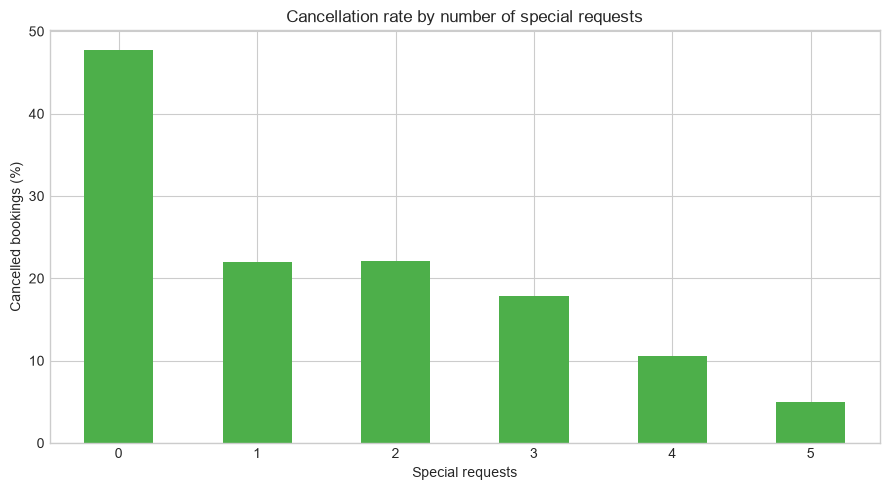

In [30]:
fig, ax = plt.subplots(figsize=(9, 5))
request_summary["cancellation_rate_pct"].plot.bar(ax=ax, color="#4daf4a")
ax.set_title("Cancellation rate by number of special requests")
ax.set_xlabel("Special requests")
ax.set_ylabel("Cancelled bookings (%)")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()


## 8. How does deposit type relate to cancellations?

Deposit type is a useful indicator of booking commitment. We compare both the number of bookings and cancellation rate by hotel so that a high rate in a very small group is not mistaken for a major business pattern.


In [31]:
deposit_summary = bookings.groupby(["hotel", "deposit_type"])["is_canceled"].agg(bookings="size", cancellation_rate="mean")
deposit_summary["cancellation_rate_pct"] = deposit_summary["cancellation_rate"] * 100
display(deposit_summary.sort_values(["hotel", "bookings"], ascending=[True, False]).round(3))


bookings  cancellation_rate  cancellation_rate_pct
hotel        deposit_type                                                    
City Hotel   No Deposit       66442              0.305                 30.469
             Non Refund       12868              0.998                 99.813
             Refundable          20              0.700                 70.000
Resort Hotel No Deposit       38199              0.247                 24.739
             Non Refund        1719              0.960                 95.986
             Refundable         142              0.155                 15.493

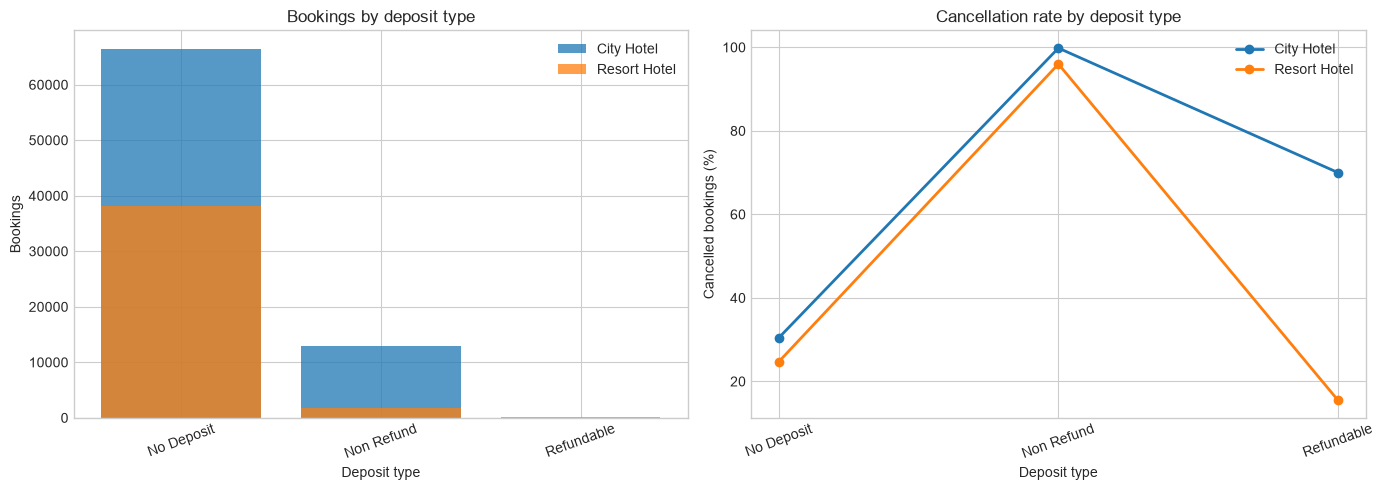

In [32]:
deposit_plot = deposit_summary.reset_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for hotel, group in deposit_plot.groupby("hotel"):
    axes[0].bar(group["deposit_type"], group["bookings"], alpha=0.75, label=hotel)
    axes[1].plot(group["deposit_type"], group["cancellation_rate_pct"], marker="o", linewidth=2, label=hotel)
axes[0].set_title("Bookings by deposit type")
axes[0].set_xlabel("Deposit type")
axes[0].set_ylabel("Bookings")
axes[1].set_title("Cancellation rate by deposit type")
axes[1].set_xlabel("Deposit type")
axes[1].set_ylabel("Cancelled bookings (%)")
for ax in axes:
    ax.legend()
    ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
plt.show()


## 9. Do repeat guests behave differently from new guests?

Repeat-guest status and previous cancellation history provide a view of customer relationship and prior booking behavior. The comparison is descriptive and should not be treated as proof that one causes the other.


In [33]:
guest_history = bookings.assign(
    guest_group=bookings["is_repeated_guest"].map({0: "New guest", 1: "Repeat guest"}),
    prior_cancellation_group=pd.cut(
        bookings["previous_cancellations"],
        bins=[-1, 0, 1, float("inf")],
        labels=["None", "One", "Two or more"],
    ),
)
guest_summary = guest_history.groupby("guest_group", observed=False)["is_canceled"].agg(bookings="size", cancellation_rate="mean")
guest_summary["cancellation_rate_pct"] = guest_summary["cancellation_rate"] * 100
prior_summary = guest_history.groupby("prior_cancellation_group", observed=False)["is_canceled"].agg(bookings="size", cancellation_rate="mean")
prior_summary["cancellation_rate_pct"] = prior_summary["cancellation_rate"] * 100
display(guest_summary.round(3))
display(prior_summary.round(3))


,bookings,cancellation_rate,cancellation_rate_pct
guest_group,,,
New guest,115580,0.378,37.785
Repeat guest,3810,0.145,14.488


,bookings,cancellation_rate,cancellation_rate_pct
prior_cancellation_group,,,
None,112906,0.339,33.906
One,6051,0.944,94.431
Two or more,433,0.527,52.656


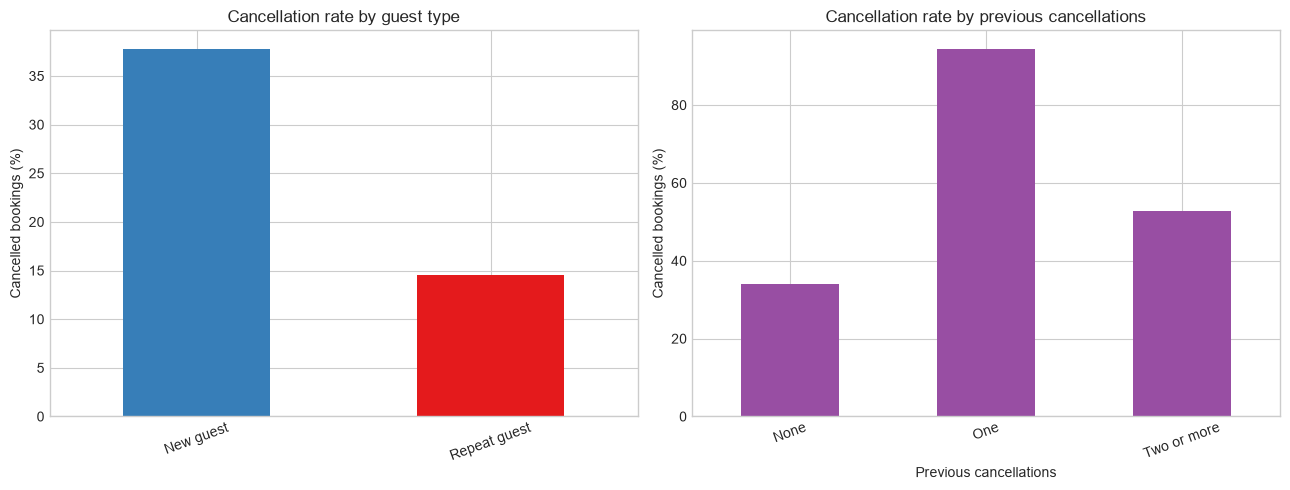

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
guest_summary["cancellation_rate_pct"].plot.bar(ax=axes[0], color=["#377eb8", "#e41a1c"])
prior_summary["cancellation_rate_pct"].plot.bar(ax=axes[1], color="#984ea3")
axes[0].set_title("Cancellation rate by guest type")
axes[0].set_xlabel("")
axes[1].set_title("Cancellation rate by previous cancellations")
axes[1].set_xlabel("Previous cancellations")
for ax in axes:
    ax.set_ylabel("Cancelled bookings (%)")
    ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
plt.show()


## 10. Does the requested room type match the assigned room type?

A mismatch between reserved and assigned room type can indicate an operational change. We compare matched and mismatched bookings by hotel and outcome, while keeping the chart focused on groups with enough observations.


In [35]:
room_match = bookings.assign(
    room_assignment=bookings["reserved_room_type"].eq(bookings["assigned_room_type"]).map({True: "Matched", False: "Mismatch"})
)
room_match_summary = room_match.groupby(["hotel", "room_assignment"])["is_canceled"].agg(bookings="size", cancellation_rate="mean")
room_match_summary["cancellation_rate_pct"] = room_match_summary["cancellation_rate"] * 100
display(room_match_summary.round(3))


bookings  cancellation_rate  \
hotel        room_assignment                                
City Hotel   Matched             72138              0.453   
             Mismatch             7192              0.058   
Resort Hotel Matched             32335              0.332   
             Mismatch             7725              0.050   

                              cancellation_rate_pct  
hotel        room_assignment                         
City Hotel   Matched                         45.308  
             Mismatch                         5.812  
Resort Hotel Matched                         33.209  
             Mismatch                         4.971

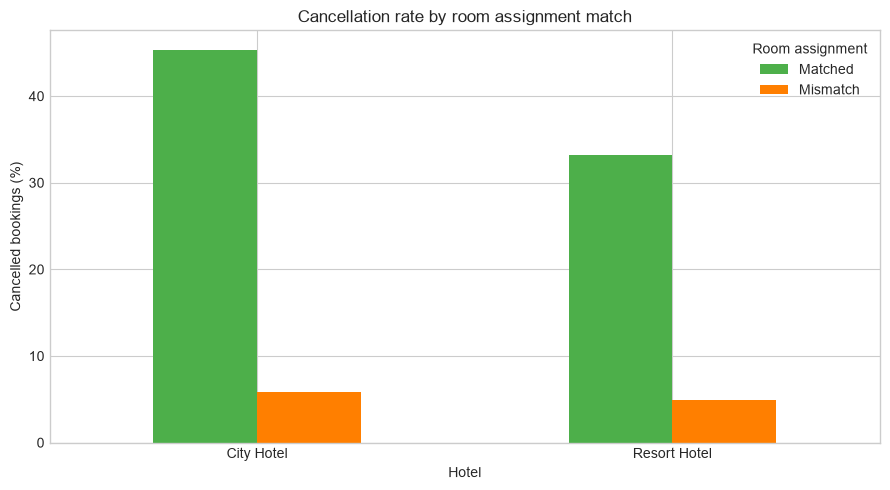

In [36]:
room_match_plot = room_match_summary["cancellation_rate_pct"].unstack()
fig, ax = plt.subplots(figsize=(9, 5))
room_match_plot.plot.bar(ax=ax, color=["#4daf4a", "#ff7f00"])
ax.set_title("Cancellation rate by room assignment match")
ax.set_xlabel("Hotel")
ax.set_ylabel("Cancelled bookings (%)")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Room assignment")
fig.tight_layout()
plt.show()


## 11. Does the mix of weekend and weekday nights matter?

Weekend and weekday nights describe the shape of a stay more precisely than total nights alone. We calculate cancellation rates for common combinations and retain the booking counts for context.


In [37]:
stay_composition = bookings.assign(
    stay_pattern=bookings["stays_in_weekend_nights"].astype(str) + " weekend / " + bookings["stays_in_week_nights"].astype(str) + " weekday"
)
stay_composition_summary = stay_composition.groupby("stay_pattern")["is_canceled"].agg(bookings="size", cancellation_rate="mean")
stay_composition_summary["cancellation_rate_pct"] = stay_composition_summary["cancellation_rate"] * 100
stay_composition_summary = stay_composition_summary.sort_values("bookings", ascending=False).head(12)
display(stay_composition_summary.round(3))


,bookings,cancellation_rate,cancellation_rate_pct
stay_pattern,,,
0 weekend / 2 weekday,17956,0.470,46.987
0 weekend / 1 weekday,16451,0.261,26.108
0 weekend / 3 weekday,11564,0.417,41.724
1 weekend / 2 weekday,8979,0.425,42.477
2 weekend / 5 weekday,8655,0.343,34.304
1 weekend / 1 weekday,7326,0.385,38.548
2 weekend / 2 weekday,6749,0.389,38.865
2 weekend / 1 weekday,6533,0.415,41.512
1 weekend / 3 weekday,6152,0.345,34.477


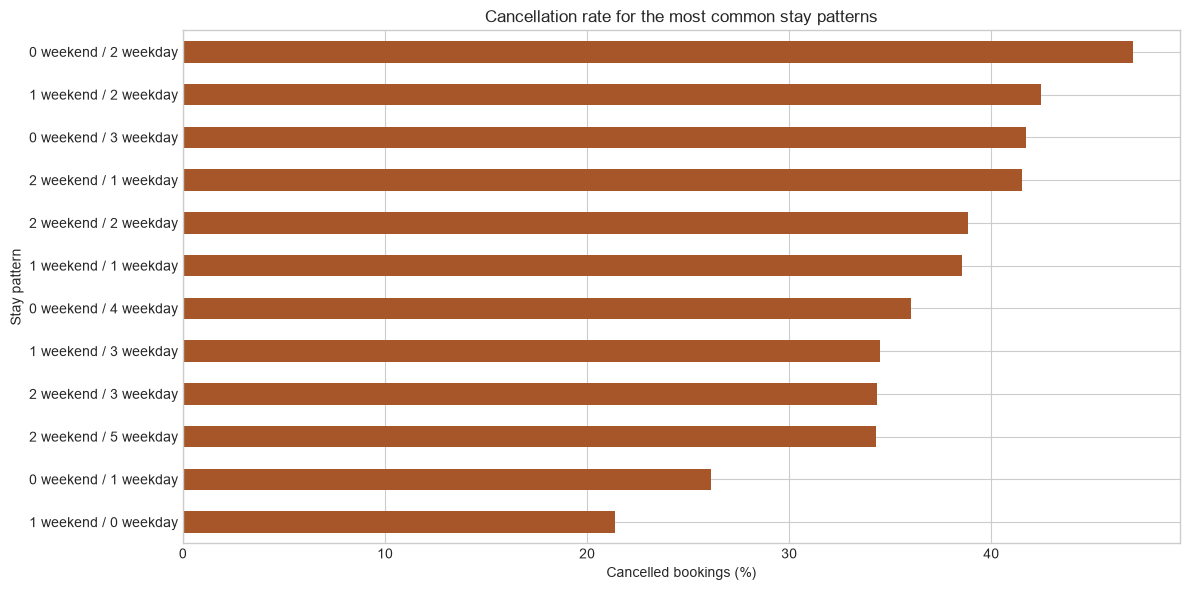

In [38]:
fig, ax = plt.subplots(figsize=(12, 6))
stay_composition_summary.sort_values("cancellation_rate_pct")["cancellation_rate_pct"].plot.barh(ax=ax, color="#a65628")
ax.set_title("Cancellation rate for the most common stay patterns")
ax.set_xlabel("Cancelled bookings (%)")
ax.set_ylabel("Stay pattern")
fig.tight_layout()
plt.show()


## 12. Are booking changes associated with cancellation?

Booking changes capture amendments made before arrival. Comparing cancellation rates across change-count bands helps identify whether stable and frequently amended bookings behave differently.


In [39]:
change_bins = [-1, 0, 1, 2, float("inf")]
change_labels = ["0", "1", "2", "3+"]
bookings["booking_change_band"] = pd.cut(bookings["booking_changes"], bins=change_bins, labels=change_labels)
change_summary = bookings.groupby("booking_change_band", observed=False)["is_canceled"].agg(bookings="size", cancellation_rate="mean")
change_summary["cancellation_rate_pct"] = change_summary["cancellation_rate"] * 100
display(change_summary.round(3))


,bookings,cancellation_rate,cancellation_rate_pct
booking_change_band,,,
0,101314,0.409,40.854
1,12701,0.142,14.227
2,3805,0.201,20.131
3+,1570,0.166,16.561


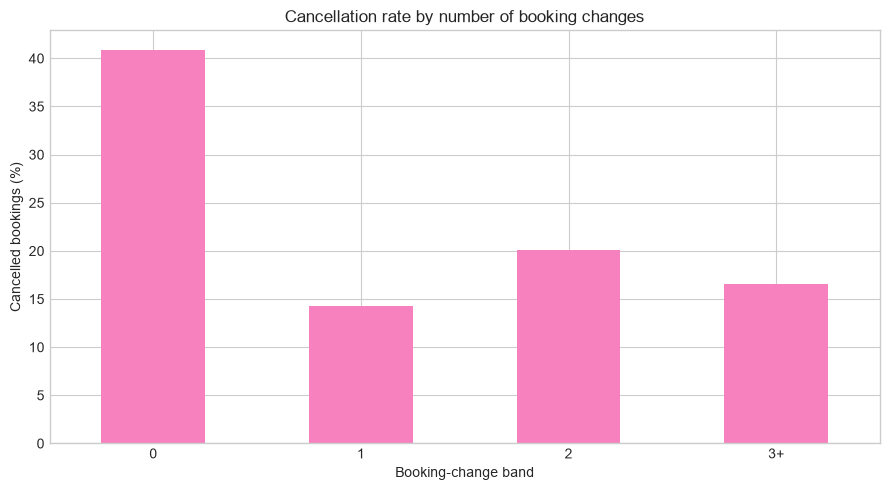

In [40]:
fig, ax = plt.subplots(figsize=(9, 5))
change_summary["cancellation_rate_pct"].plot.bar(ax=ax, color="#f781bf")
ax.set_title("Cancellation rate by number of booking changes")
ax.set_xlabel("Booking-change band")
ax.set_ylabel("Cancelled bookings (%)")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()


## 13. Which arrival weekdays have the most cancellations?

Arrival weekday can reveal differences between weekend and midweek demand. We compare booking volume and cancellation rate by hotel and weekday.


In [ ]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_data = bookings.assign(arrival_weekday=bookings["arrival_date"].dt.day_name())
weekday_summary = weekday_data.groupby(["arrival_weekday", "hotel"])["is_canceled"].agg(bookings="size", cancellation_rate="mean")
weekday_summary["cancellation_rate_pct"] = weekday_summary["cancellation_rate"] * 100
weekday_summary = weekday_summary.reindex(pd.MultiIndex.from_product([weekday_order, bookings["hotel"].unique()], names=["arrival_weekday", "hotel"]))
display(weekday_summary.round(3))


In [ ]:
weekday_rates = weekday_summary["cancellation_rate_pct"].unstack()
fig, ax = plt.subplots(figsize=(11, 5))
weekday_rates.plot(ax=ax, marker="o", linewidth=2)
ax.set_title("Cancellation rate by arrival weekday")
ax.set_xlabel("Arrival weekday")
ax.set_ylabel("Cancelled bookings (%)")
ax.tick_params(axis="x", rotation=20)
ax.legend(title="Hotel")
fig.tight_layout()
plt.show()


## 14. Does lead-time behavior differ between the hotels?

The earlier lead-time analysis combined both hotels. This interaction view checks whether the same lead-time bands behave differently at City Hotel and Resort Hotel.


In [ ]:
lead_hotel_summary = bookings.groupby(["lead_time_band", "hotel"], observed=False)["is_canceled"].agg(bookings="size", cancellation_rate="mean")
lead_hotel_summary["cancellation_rate_pct"] = lead_hotel_summary["cancellation_rate"] * 100
display(lead_hotel_summary.round(3))


In [ ]:
lead_hotel_rates = lead_hotel_summary["cancellation_rate_pct"].unstack()
fig, ax = plt.subplots(figsize=(11, 5))
lead_hotel_rates.plot(ax=ax, marker="o", linewidth=2)
ax.set_title("Cancellation rate by lead-time band and hotel")
ax.set_xlabel("Booking lead-time band")
ax.set_ylabel("Cancelled bookings (%)")
ax.legend(title="Hotel")
fig.tight_layout()
plt.show()


## 15. What happens when a booking spends time on the waiting list?

Waiting-list days describe how long a booking was held before confirmation. We group this operational measure into clear bands and compare cancellation rates.


In [ ]:
waiting_bins = [-1, 0, 3, 7, 14, 30, float("inf")]
waiting_labels = ["0", "1-3", "4-7", "8-14", "15-30", "31+"]
bookings["waiting_list_band"] = pd.cut(bookings["days_in_waiting_list"], bins=waiting_bins, labels=waiting_labels)
waiting_summary = bookings.groupby("waiting_list_band", observed=False)["is_canceled"].agg(bookings="size", cancellation_rate="mean")
waiting_summary["cancellation_rate_pct"] = waiting_summary["cancellation_rate"] * 100
display(waiting_summary.round(3))


In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
waiting_summary["cancellation_rate_pct"].plot.bar(ax=ax, color="#377eb8")
ax.set_title("Cancellation rate by waiting-list duration")
ax.set_xlabel("Waiting-list days")
ax.set_ylabel("Cancelled bookings (%)")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()


## 16. Are parking requests associated with cancellation?

Parking requests are a simple proxy for practical travel planning. We compare cancellation rates for each request count while retaining booking volume.


In [ ]:
parking_summary = bookings.groupby("required_car_parking_spaces")["is_canceled"].agg(bookings="size", cancellation_rate="mean")
parking_summary["cancellation_rate_pct"] = parking_summary["cancellation_rate"] * 100
display(parking_summary.round(3))


In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
parking_summary["cancellation_rate_pct"].plot.bar(ax=ax, color="#4daf4a")
ax.set_title("Cancellation rate by requested parking spaces")
ax.set_xlabel("Requested parking spaces")
ax.set_ylabel("Cancelled bookings (%)")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()


## 17. Does the presence of family members change cancellation behavior?

We classify bookings as solo, couple, family, or group based on adults, children, babies, and the number of people. This provides a compact view of booking-party structure.


In [ ]:
family_data = bookings.assign(
    total_guests=bookings["adults"] + bookings["children"] + bookings["babies"],
)
family_data["party_type"] = "Group"
family_data.loc[(family_data["total_guests"] == 1), "party_type"] = "Solo"
family_data.loc[(family_data["total_guests"] == 2) & (family_data["children"] + family_data["babies"] == 0), "party_type"] = "Couple"
family_data.loc[(family_data["children"] + family_data["babies"] > 0), "party_type"] = "Family"
party_summary = family_data.groupby("party_type")["is_canceled"].agg(bookings="size", cancellation_rate="mean").reindex(["Solo", "Couple", "Family", "Group"])
party_summary["cancellation_rate_pct"] = party_summary["cancellation_rate"] * 100
display(party_summary.round(3))


In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
party_summary["cancellation_rate_pct"].plot.bar(ax=ax, color="#984ea3")
ax.set_title("Cancellation rate by booking-party type")
ax.set_xlabel("Party type")
ax.set_ylabel("Cancelled bookings (%)")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()


## 18. Which origin countries contribute the most bookings?

Country counts show where demand comes from. We focus on the 15 largest origin groups, because rates from countries with only a few bookings can be misleading.


In [ ]:
country_summary = bookings.groupby("country")["is_canceled"].agg(bookings="size", cancellation_rate="mean")
country_summary["cancellation_rate_pct"] = country_summary["cancellation_rate"] * 100
top_countries = country_summary.sort_values("bookings", ascending=False).head(15)
display(top_countries.round(3))


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
top_countries["bookings"].sort_values().plot.barh(ax=axes[0], color="#377eb8")
top_countries["cancellation_rate_pct"].sort_values().plot.barh(ax=axes[1], color="#e41a1c")
axes[0].set_title("Top origin countries by bookings")
axes[0].set_xlabel("Bookings")
axes[1].set_title("Cancellation rate for top origin countries")
axes[1].set_xlabel("Cancelled bookings (%)")
fig.tight_layout()
plt.show()


## 19. Does market segment behavior differ by hotel?

Market segment can represent different customer acquisition routes. We compare cancellation rates within each hotel and retain booking counts for context.


In [ ]:
segment_hotel_summary = bookings.groupby(["market_segment", "hotel"])["is_canceled"].agg(bookings="size", cancellation_rate="mean")
segment_hotel_summary["cancellation_rate_pct"] = segment_hotel_summary["cancellation_rate"] * 100
display(segment_hotel_summary.sort_values("bookings", ascending=False).round(3))


In [ ]:
segment_hotel_rates = segment_hotel_summary["cancellation_rate_pct"].unstack()
fig, ax = plt.subplots(figsize=(12, 6))
segment_hotel_rates.plot.bar(ax=ax)
ax.set_title("Cancellation rate by market segment and hotel")
ax.set_xlabel("Market segment")
ax.set_ylabel("Cancelled bookings (%)")
ax.tick_params(axis="x", rotation=35)
ax.legend(title="Hotel")
fig.tight_layout()
plt.show()


## 20. Does cancellation vary across ADR bands?

Grouping ADR into bands helps reveal whether lower- and higher-priced bookings have different cancellation behavior. We use quantile bands so each group has a substantial number of observations.


In [ ]:
adr_data = bookings.loc[bookings["adr"] >= 0].copy()
adr_data["adr_band"] = pd.qcut(adr_data["adr"], q=5, duplicates="drop")
adr_band_summary = adr_data.groupby("adr_band", observed=False)["is_canceled"].agg(bookings="size", median_adr="median", cancellation_rate="mean")
adr_band_summary["cancellation_rate_pct"] = adr_band_summary["cancellation_rate"] * 100
display(adr_band_summary.round(3))


In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
adr_band_summary["cancellation_rate_pct"].plot.bar(ax=ax, color="#ff7f00")
ax.set_title("Cancellation rate across ADR bands")
ax.set_xlabel("ADR quantile band")
ax.set_ylabel("Cancelled bookings (%)")
ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
plt.show()


## 21. Did booking volume and cancellations change by arrival year?

Year-level comparison gives a broad stability check across the dataset period. It is descriptive and does not replace the required chronological train, choose, and proof evaluation.


In [ ]:
year_summary = bookings.assign(arrival_year=bookings["arrival_date"].dt.year).groupby("arrival_year")["is_canceled"].agg(bookings="size", cancellation_rate="mean")
year_summary["cancellation_rate_pct"] = year_summary["cancellation_rate"] * 100
display(year_summary.round(3))


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
year_summary["bookings"].plot.bar(ax=axes[0], color="#4daf4a")
year_summary["cancellation_rate_pct"].plot.bar(ax=axes[1], color="#984ea3")
axes[0].set_title("Bookings by arrival year")
axes[0].set_xlabel("Arrival year")
axes[0].set_ylabel("Bookings")
axes[1].set_title("Cancellation rate by arrival year")
axes[1].set_xlabel("Arrival year")
axes[1].set_ylabel("Cancelled bookings (%)")
for ax in axes:
    ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()


## Exploratory takeaways

Use these charts to guide questions and later modeling, not to make final causal claims. The strongest follow-up questions are: how seasonal cancellation patterns should affect buffers, whether lead time adds predictive value, how booking commitment and customer history relate to cancellations, how operational waiting and arrival timing matter, and how geography, segment, price, and time stability should be handled without over-interpreting small groups.
